
# CS5344 — Synthetic Normal-Data Generation
## Conditional Gaussian-Copula Augmentation for NSL-KDD & UNSW-NB15

**What this notebook does.** Building directly on `EDA.ipynb`'s conclusions, this notebook
implements, validates, and exports the actual Kaggle submission: a fixed-size, normal-only
synthetic dataset per competition dataset.

**Method summary (one transferable pipeline, per-dataset parameters).**
1. **Category-first sampling.** The categorical columns are resampled jointly from their
   empirical frequency table, which by construction preserves the Cramér's V association
   between them (Section 1.5/2.5 of the EDA) exactly.
2. **Conditional Gaussian copula for the rest.** Conditional on the primary protocol column
   (`protocol_type` for NSL-KDD, a bucketed `proto` for UNSW-NB15 — chosen because the EDA's
   domain-constraint checks showed protocol is what structurally determines which numeric
   fields are even non-zero, e.g. TCP-only fields for non-TCP flows), continuous/binary/
   small-integer columns are generated with a **Gaussian copula**: empirical marginals per
   protocol group (so byte-count distributions differ by protocol, matching the EDA) plus a
   shrunk, eigenvalue-corrected correlation matrix per group (so the strong inter-feature
   correlations found in Section 1.5/2.5 are preserved, not sampled independently).
3. **Deterministic constraint enforcement.** The exact algebraic/logical relations the EDA
   verified hold with ~0 violations in real data (`tcprtt = synack + ackdat`, TCP-only fields
   zeroed for non-TCP, no root shell without login) are **re-imposed after sampling**, because
   a statistical copula will not reproduce an exact identity on its own. Range/allowed-set
   rules from `eda_outputs/*_constraints.json` are then clipped/snapped as a final safety net.
4. **Local proxy evaluation before spending Kaggle submissions.** A held-out split of the
   *real, labeled* training data (never used to fit the generator) lets us run the same
   fixed-detector recipe described in the briefing (ECOD + 10-seed × 500-tree IsolationForest,
   scored by AUPRC) locally, to compare our copula generator against the starter kit's
   bootstrap+jitter baseline and against a real-data upper bound — before using a limited daily
   Kaggle submission.

**Explicit caveats (stated up front for the report).** The organizers' exact fixed training
scheme (preprocessing, scaling, categorical encoding) is not disclosed beyond "ECOD" and
"IsolationForest, 10 seeds × 500 trees", so the local proxy AUPRC below is a **directional**
signal, not a prediction of the Kaggle score. The local holdout also cannot contain the
unseen anomaly types that the real hidden validation/test sets do, so it will be optimistic
about generalization to novel attacks.


In [1]:

import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score
from pyod.models.ecod import ECOD

sys.path.insert(0, ".")
from pipeline_utils import (
    RANDOM_SEED, LABEL_COL, split_feature_types, bucket_rare_categories,
    scrub_normal, nearest_pd_correlation, apply_numeric_constraints,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 9, "axes.labelsize": 8})

rng = np.random.default_rng(RANDOM_SEED)

EDA_DIR = Path("eda_outputs")
SUB_DIR = Path("submissions")
SUB_DIR.mkdir(exist_ok=True)

CONFIG = {
    "NSL-KDD": {
        "path": "train_nslkdd.csv", "slug": "nslkdd",
        "group_col": "protocol_type", "high_card_cols": ["service"],
        "target_n": 40000,
    },
    "UNSW-NB15": {
        "path": "train_unsw.csv", "slug": "unsw",
        "group_col": "proto", "high_card_cols": ["proto"],
        "target_n": 70000,
    },
}
RARE_CATEGORY_MIN_FREQ = 0.01
MIN_GROUP_SIZE = 50
CONTAMINATION = 0.02
N_IFOREST_SEEDS = 10
N_IFOREST_TREES = 500



## 0. Generator building blocks

Two mechanisms, used together for every dataset:

- `fit_categorical_sampler` / `sample_categorical` — resample categorical *tuples* from their
  observed joint frequency (not column-by-column), so co-occurrence patterns (e.g. which
  `service` values pair with which `flag`) are preserved by construction.
- `fit_conditional_copula` / `sample_conditional_copula` — a Gaussian copula with **empirical
  marginals estimated per protocol group** (shrunk toward the global marginal/correlation for
  small groups via `n / (n + 100)` weighting, to avoid overfitting rare protocol groups) for
  the remaining numeric columns. Sampling: draw correlated standard-normal vectors via a
  Cholesky factor of the (eigenvalue-corrected) group correlation matrix, map to uniforms via
  the normal CDF, then invert each column's empirical CDF by interpolating on its sorted
  training values.


In [2]:

def fit_categorical_sampler(df: pd.DataFrame, cat_cols: list) -> pd.Series:
    counts = df.groupby(cat_cols, observed=True).size()
    return (counts / counts.sum()).rename("p")


def sample_categorical(probs: pd.Series, n: int, rng: np.random.Generator) -> pd.DataFrame:
    idx = rng.choice(len(probs), size=n, p=probs.to_numpy())
    combos = probs.index[idx]
    cols = list(probs.index.names)
    if len(cols) == 1:
        return pd.DataFrame({cols[0]: combos.to_numpy()})
    arr = np.array(list(combos))
    return pd.DataFrame({c: arr[:, i] for i, c in enumerate(cols)})


def fit_conditional_copula(df: pd.DataFrame, cols: list, group_col: str,
                            min_group_size: int = MIN_GROUP_SIZE) -> dict:
    n_all = len(df)
    global_sorted = {c: np.sort(df[c].to_numpy(dtype=float)) for c in cols}
    global_scores = pd.DataFrame(
        {c: stats.norm.ppf(stats.rankdata(df[c]) / (n_all + 1)) for c in cols}, index=df.index
    )
    global_corr = nearest_pd_correlation(global_scores.corr().fillna(0).to_numpy())

    groups_fit = {}
    for g, gdf in df.groupby(group_col, observed=True):
        m = len(gdf)
        if m >= min_group_size:
            marg = {c: np.sort(gdf[c].to_numpy(dtype=float)) for c in cols}
            local_corr = global_scores.loc[gdf.index].corr().fillna(0).to_numpy().copy()
            np.fill_diagonal(local_corr, 1.0)
            w = m / (m + 100)
            corr = nearest_pd_correlation(w * local_corr + (1 - w) * global_corr)
        else:
            marg, corr = global_sorted, global_corr
        groups_fit[g] = {"marginals": marg, "corr": corr, "n": m}

    return {"groups": groups_fit, "columns": cols, "global_corr": global_corr, "global_marginals": global_sorted}


def sample_conditional_copula(fit: dict, group_labels: pd.Series, rng: np.random.Generator) -> pd.DataFrame:
    cols = fit["columns"]
    group_labels = pd.Series(group_labels).reset_index(drop=True)
    n = len(group_labels)
    out = np.empty((n, len(cols)))
    for g in group_labels.unique():
        mask = (group_labels == g).to_numpy()
        m = int(mask.sum())
        gfit = fit["groups"].get(g, {"marginals": fit["global_marginals"], "corr": fit["global_corr"]})
        L = np.linalg.cholesky(gfit["corr"])
        z = rng.standard_normal((m, len(cols))) @ L.T
        u = stats.norm.cdf(z)
        for j, c in enumerate(cols):
            sv = gfit["marginals"][c]
            q = u[:, j] * (len(sv) - 1)
            out[mask, j] = np.interp(q, np.arange(len(sv)), sv)
    return pd.DataFrame(out, columns=cols)



## 1. Constraint enforcement & submission assembly

`enforce_hard_relations` re-imposes the exact logical/algebraic identities the EDA verified
hold (near-)universally in real data but that a statistical copula cannot be trusted to
reproduce exactly. `assemble_submission` glues categorical + copula-generated columns back
into the original column order, hardcodes known zero-variance columns, applies the JSON
constraint spec, and runs the starter kit's own validation checklist.


In [3]:

def enforce_hard_relations(df: pd.DataFrame, dataset_name: str) -> pd.DataFrame:
    df = df.copy()
    if dataset_name == "NSL-KDD":
        no_login = df["logged_in"] == 0
        n_fix = int((no_login & ((df["root_shell"] == 1) | (df["su_attempted"] > 0))).sum())
        df.loc[no_login, "root_shell"] = 0
        df.loc[no_login, "su_attempted"] = 0
        print(f"  root_privilege_requires_login: corrected {n_fix} rows")
    elif dataset_name == "UNSW-NB15":
        non_tcp = df["proto"] != "tcp"
        n_fix = int((non_tcp & ((df["swin"] != 0) | (df["dwin"] != 0) | (df["stcpb"] != 0) | (df["dtcpb"] != 0))).sum())
        for c in ["swin", "dwin", "stcpb", "dtcpb"]:
            df.loc[non_tcp, c] = 0
        print(f"  nontcp_fields_zeroed: corrected {n_fix} rows")
        drift = (df["tcprtt"] - (df["synack"] + df["ackdat"])).abs()
        n_drift = int((drift > 1e-9).sum())
        df["tcprtt"] = df["synack"] + df["ackdat"]
        print(f"  tcprtt_consistency: recomputed for {n_drift} rows with drift > 1e-9")
    return df


def round_integer_like(df: pd.DataFrame, seed_df: pd.DataFrame, numeric_cols: list) -> pd.DataFrame:
    '''Snap generated values back to integers for columns that are integer-valued in the seed data.'''
    df = df.copy()
    for c in numeric_cols:
        if c not in df.columns:
            continue
        seed_vals = seed_df[c].dropna().to_numpy()
        if len(seed_vals) and np.all(np.isclose(seed_vals, np.round(seed_vals))):
            lo, hi = seed_vals.min(), seed_vals.max()
            df[c] = np.rint(df[c].clip(lo, hi))
    return df


def assemble_submission(cat_df: pd.DataFrame, copula_df: pd.DataFrame, feature_cols: list,
                         const_cols: dict, dataset_name: str, seed_df: pd.DataFrame,
                         numeric_cols: list, constraint_spec: dict) -> pd.DataFrame:
    n = len(cat_df)
    out = pd.DataFrame(index=range(n))
    for c in feature_cols:
        if c in const_cols:
            out[c] = const_cols[c]
        elif c in cat_df.columns:
            out[c] = cat_df[c].to_numpy()
        elif c in copula_df.columns:
            out[c] = copula_df[c].to_numpy()
        else:
            raise ValueError(f"Column '{c}' not produced by any generator stage.")

    out = round_integer_like(out, seed_df, numeric_cols)
    print("Enforcing hard logical/algebraic relations:")
    out = enforce_hard_relations(out, dataset_name)
    out = apply_numeric_constraints(out, constraint_spec)
    out = round_integer_like(out, seed_df, numeric_cols)  # constraint clipping can reintroduce non-integers
    return out[feature_cols]


def validate_submission(df: pd.DataFrame, feature_cols: list, target_n: int) -> None:
    assert len(df) == target_n, f"Expected {target_n} rows, got {len(df)}"
    assert list(df.columns) == feature_cols, "Column set/order mismatch vs. training schema"
    assert not df.isna().any().any(), "Submission contains NaNs"
    numeric_part = df.select_dtypes(include=[np.number]).to_numpy(dtype=float)
    assert np.isfinite(numeric_part).all(), "Submission contains inf values"
    print(f"Validation passed: {df.shape[0]} rows x {df.shape[1]} columns, no NaN/inf, schema matches training data.")


def bootstrap_jitter_baseline(seed_df: pd.DataFrame, continuous_cols: list, n: int,
                               jitter_scale: float = 0.5, rng: np.random.Generator = None) -> pd.DataFrame:
    '''Starter-kit-style baseline: bootstrap real rows + Gaussian jitter on continuous columns.'''
    rng = rng or np.random.default_rng(RANDOM_SEED)
    idx = rng.integers(0, len(seed_df), size=n)
    synth = seed_df.iloc[idx].reset_index(drop=True).copy()
    for c in continuous_cols:
        std = seed_df[c].std(ddof=0)
        if not np.isfinite(std) or std == 0:
            continue
        synth[c] = synth[c].astype(float) + rng.normal(0, jitter_scale * std, n)
        lo, hi = seed_df[c].min(), seed_df[c].max()
        synth[c] = synth[c].clip(lo, hi)
    return synth



## 2. Local proxy evaluation harness

Reproduces the briefing's scoring recipe as closely as the public information allows:
**ECOD** (deterministic) and **IsolationForest with 10 fixed seeds × 500 trees** (averaged),
combined as `S = (AUPRC_ECOD + AUPRC_IForest) / 2`, trained on a candidate normal-only dataset
and scored on a labeled holdout via `average_precision_score` (AUPRC).


In [4]:

def build_dummy_reference(df: pd.DataFrame, cat_cols: list) -> list:
    return pd.get_dummies(df[cat_cols]).columns.tolist()


def to_feature_matrix(df: pd.DataFrame, numeric_cols: list, cat_cols: list, ref_dummy_cols: list,
                       scaler: StandardScaler = None):
    X_num = df[numeric_cols].to_numpy(dtype=float)
    if scaler is None:
        scaler = StandardScaler().fit(X_num)
    X_num_s = scaler.transform(X_num)
    X_cat = pd.get_dummies(df[cat_cols]).reindex(columns=ref_dummy_cols, fill_value=0).to_numpy(dtype=float)
    return np.hstack([X_num_s, X_cat]), scaler


def evaluate_candidate(train_df: pd.DataFrame, holdout_df: pd.DataFrame, numeric_cols: list,
                        cat_cols: list, ref_dummy_cols: list, label_col: str = LABEL_COL,
                        n_seeds: int = N_IFOREST_SEEDS, n_trees: int = N_IFOREST_TREES) -> dict:
    X_train, scaler = to_feature_matrix(train_df, numeric_cols, cat_cols, ref_dummy_cols)
    X_holdout, _ = to_feature_matrix(holdout_df, numeric_cols, cat_cols, ref_dummy_cols, scaler=scaler)
    y_holdout = holdout_df[label_col].to_numpy()

    ecod = ECOD()
    ecod.fit(X_train)
    auprc_ecod = average_precision_score(y_holdout, ecod.decision_function(X_holdout))

    iforest_scores = []
    for seed in range(n_seeds):
        clf = IsolationForest(n_estimators=n_trees, random_state=seed, n_jobs=-1)
        clf.fit(X_train)
        iforest_scores.append(average_precision_score(y_holdout, -clf.score_samples(X_holdout)))
    auprc_iforest = float(np.mean(iforest_scores))

    return {"AUPRC_ECOD": auprc_ecod, "AUPRC_IForest": auprc_iforest,
            "S": (auprc_ecod + auprc_iforest) / 2, "IForest_seed_scores": iforest_scores}



## 3. Per-dataset pipeline

The function below runs the full pipeline for one dataset: holdout split → scrub → fit
generator on the 80% split → local proxy evaluation (copula vs. bootstrap+jitter baseline vs.
a real-data upper bound) → refit the generator on **100%** of the scrubbed normal data → fidelity
diagnostics → generate, constrain, validate, and export the actual submission.


In [5]:

def run_pipeline(name: str) -> dict:
    cfg = CONFIG[name]
    print("#" * 90)
    print(f"# {name}")
    print("#" * 90)

    df = pd.read_csv(cfg["path"])
    types = split_feature_types(df)
    feature_cols = types["feature_cols"]
    continuous_cols = types["continuous_cols"]
    binary_cols = types["binary_cols"]
    categorical_cols = types["categorical_cols"]
    numeric_cols = types["numeric_cols"]

    const_cols = {c: 0 for c in numeric_cols if df[c].nunique() == 1}
    copula_numeric_cols = [c for c in numeric_cols if c not in const_cols]
    print(f"Hardcoded zero-variance columns (excluded from modelling): {list(const_cols)}")

    with open(EDA_DIR / f"{cfg['slug']}_constraints.json") as f:
        constraint_spec = json.load(f)

    # ---- 80/20 holdout split for an honest local proxy (no leakage into the generator) ----
    gen_source, local_holdout = train_test_split(
        df, test_size=0.2, stratify=df[LABEL_COL], random_state=RANDOM_SEED
    )
    seed_80 = scrub_normal(gen_source, continuous_cols, contamination=CONTAMINATION)
    print(f"\n80% generator-fitting split: {len(gen_source)} rows -> {len(seed_80)} scrubbed normals")
    print(f"20% local holdout (never used for fitting): {len(local_holdout)} rows "
          f"({local_holdout[LABEL_COL].mean():.1%} abnormal)")

    def fit_and_generate(seed_df: pd.DataFrame, n: int) -> pd.DataFrame:
        cat_bucketed = seed_df.copy()
        for c in cfg["high_card_cols"]:
            cat_bucketed[c] = bucket_rare_categories(cat_bucketed[c], min_freq=RARE_CATEGORY_MIN_FREQ)
        cat_probs = fit_categorical_sampler(cat_bucketed, categorical_cols)
        cat_synth = sample_categorical(cat_probs, n, rng)

        group_source = cat_bucketed[cfg["group_col"]] if cfg["group_col"] in cfg["high_card_cols"] else seed_df[cfg["group_col"]]
        copula_fit_cols = [c for c in copula_numeric_cols]
        copula_fit = fit_conditional_copula(seed_df.assign(**{cfg["group_col"]: group_source}),
                                             copula_fit_cols, cfg["group_col"])
        copula_synth = sample_conditional_copula(copula_fit, cat_synth[cfg["group_col"]], rng)
        return assemble_submission(cat_synth, copula_synth, feature_cols, const_cols, name,
                                    seed_df, numeric_cols, constraint_spec)

    # ---- Local proxy evaluation: copula vs. bootstrap+jitter vs. real-data ceiling ----
    n_proxy = cfg["target_n"]
    synth_proxy = fit_and_generate(seed_80, n_proxy)
    baseline_proxy = bootstrap_jitter_baseline(seed_80, continuous_cols, n_proxy, rng=rng)[feature_cols]
    real_ceiling_proxy = seed_80.sample(
        n=n_proxy, replace=n_proxy > len(seed_80), random_state=RANDOM_SEED
    )[feature_cols]

    ref_dummy_cols = build_dummy_reference(df, categorical_cols)
    results = {}
    for label, candidate in [("copula_generator", synth_proxy),
                              ("bootstrap_jitter_baseline", baseline_proxy),
                              ("real_normal_ceiling", real_ceiling_proxy)]:
        res = evaluate_candidate(candidate, local_holdout, numeric_cols, categorical_cols, ref_dummy_cols)
        results[label] = res
        print(f"\n[{label}] AUPRC_ECOD={res['AUPRC_ECOD']:.4f}  AUPRC_IForest={res['AUPRC_IForest']:.4f}  S={res['S']:.4f}")

    proxy_table = pd.DataFrame(results).T[["AUPRC_ECOD", "AUPRC_IForest", "S"]]
    display(proxy_table)

    fig, ax = plt.subplots(figsize=(5, 3.2))
    ax.bar(proxy_table.index, proxy_table["S"], color=["#4C72B0", "#C44E52", "#55A868"])
    ax.set_ylabel("Local proxy S = (AUPRC_ECOD + AUPRC_IForest) / 2")
    ax.set_title(f"Local proxy leaderboard score — {name}")
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.show()

    # ---- Refit on 100% of the scrubbed normal data for the actual submission ----
    seed_full = scrub_normal(df, continuous_cols, contamination=CONTAMINATION)
    print(f"\nFull scrubbed normal set for final submission: {len(seed_full)} rows "
          f"(required submission size N={cfg['target_n']}; "
          f"{cfg['target_n'] / len(seed_full):.2f}x the unique real-normal rows available, "
          f"so most submitted rows must be genuinely interpolated, not replayed real rows).")
    submission = fit_and_generate(seed_full, cfg["target_n"])
    validate_submission(submission, feature_cols, cfg["target_n"])

    out = submission.copy()
    out.insert(0, "id", np.arange(len(out)))
    out_path = SUB_DIR / f"submission_{cfg['slug']}.csv"
    out.to_csv(out_path, index=False)
    print(f"Saved submission -> {out_path}  shape={out.shape}")

    return {
        "types": types, "seed_full": seed_full, "submission": submission,
        "proxy_table": proxy_table, "feature_cols": feature_cols,
        "categorical_cols": categorical_cols, "numeric_cols": numeric_cols,
    }



## 4. Fidelity diagnostics

Fidelity is **not** the grading metric (utility is), but a generator that visibly fails to
reproduce basic real-data structure is a red flag worth catching before a Kaggle submission.
We compare the final submission against the full scrubbed real-normal set on: marginal
distributions, the numeric correlation matrix, and categorical frequencies.


In [6]:

def fidelity_diagnostics(name: str, result: dict, top_k: int = 10):
    real = result["seed_full"]
    synth = result["submission"]
    numeric_cols = result["numeric_cols"]
    cat_cols = result["categorical_cols"]

    variances = real[numeric_cols].var().sort_values(ascending=False)
    top_cols = variances.head(top_k).index.tolist()

    fig, axes = plt.subplots(2, 5, figsize=(18, 6))
    axes = axes.reshape(-1)
    for i, c in enumerate(top_cols):
        sns.kdeplot(real[c], ax=axes[i], color="#4C72B0", label="real (scrubbed normal)", fill=True, alpha=0.3)
        sns.kdeplot(synth[c], ax=axes[i], color="#C44E52", label="synthetic", fill=True, alpha=0.3)
        axes[i].set_title(c, fontsize=8)
        axes[i].set_xlabel("")
        if i == 0:
            axes[i].legend(fontsize=6)
    fig.suptitle(f"Real vs. synthetic marginals (top-{top_k} variance features) — {name}", y=1.02)
    plt.tight_layout()
    plt.show()

    real_corr = real[numeric_cols].corr()
    synth_corr = synth[numeric_cols].corr()
    diff = (real_corr - synth_corr).abs()
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    for ax, mat, title, cmap, vmax in [
        (axes[0], real_corr, "Real correlation", "RdBu_r", 1),
        (axes[1], synth_corr, "Synthetic correlation", "RdBu_r", 1),
        (axes[2], diff, "|Real - Synthetic|", "viridis", None),
    ]:
        sns.heatmap(mat, ax=ax, cmap=cmap, vmin=-1 if vmax else None, vmax=vmax,
                    xticklabels=False, yticklabels=False, cbar_kws={"shrink": 0.6})
        ax.set_title(title, fontsize=9)
    fig.suptitle(f"Correlation-structure fidelity — {name}", y=1.03)
    plt.tight_layout()
    plt.show()
    print(f"Mean absolute correlation error: {diff.to_numpy()[np.triu_indices(len(diff), k=1)].mean():.4f}")

    fig, axes = plt.subplots(1, len(cat_cols), figsize=(6 * len(cat_cols), 3.6))
    if len(cat_cols) == 1:
        axes = [axes]
    for ax, c in zip(axes, cat_cols):
        real_top = real[c].value_counts(normalize=True).head(8)
        synth_freq = synth[c].value_counts(normalize=True).reindex(real_top.index, fill_value=0)
        x = np.arange(len(real_top))
        ax.bar(x - 0.2, real_top.values, width=0.4, label="real", color="#4C72B0")
        ax.bar(x + 0.2, synth_freq.values, width=0.4, label="synthetic", color="#C44E52")
        ax.set_xticks(x)
        ax.set_xticklabels(real_top.index, rotation=45, ha="right", fontsize=7)
        ax.set_title(c)
        ax.legend(fontsize=7)
    fig.suptitle(f"Categorical frequency fidelity — {name}", y=1.05)
    plt.tight_layout()
    plt.show()


## 5. Run — NSL-KDD

##########################################################################################
# NSL-KDD
##########################################################################################
Hardcoded zero-variance columns (excluded from modelling): ['num_outbound_cmds', 'is_host_login']



80% generator-fitting split: 24000 rows -> 15680 scrubbed normals
20% local holdout (never used for fitting): 6000 rows (33.3% abnormal)


Enforcing hard logical/algebraic relations:
  root_privilege_requires_login: corrected 8 rows



[copula_generator] AUPRC_ECOD=0.9383  AUPRC_IForest=0.9631  S=0.9507



[bootstrap_jitter_baseline] AUPRC_ECOD=0.9406  AUPRC_IForest=0.9636  S=0.9521



[real_normal_ceiling] AUPRC_ECOD=0.9405  AUPRC_IForest=0.9691  S=0.9548


,AUPRC_ECOD,AUPRC_IForest,S
copula_generator,0.938274,0.963128,0.950701
bootstrap_jitter_baseline,0.940627,0.963588,0.952108
real_normal_ceiling,0.940498,0.969082,0.95479


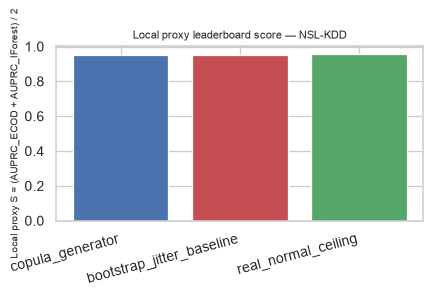


Full scrubbed normal set for final submission: 19600 rows (required submission size N=40000; 2.04x the unique real-normal rows available, so most submitted rows must be genuinely interpolated, not replayed real rows).


Enforcing hard logical/algebraic relations:
  root_privilege_requires_login: corrected 6 rows
Validation passed: 40000 rows x 41 columns, no NaN/inf, schema matches training data.


Saved submission -> submissions/submission_nslkdd.csv  shape=(40000, 42)


In [7]:
nslkdd_result = run_pipeline("NSL-KDD")

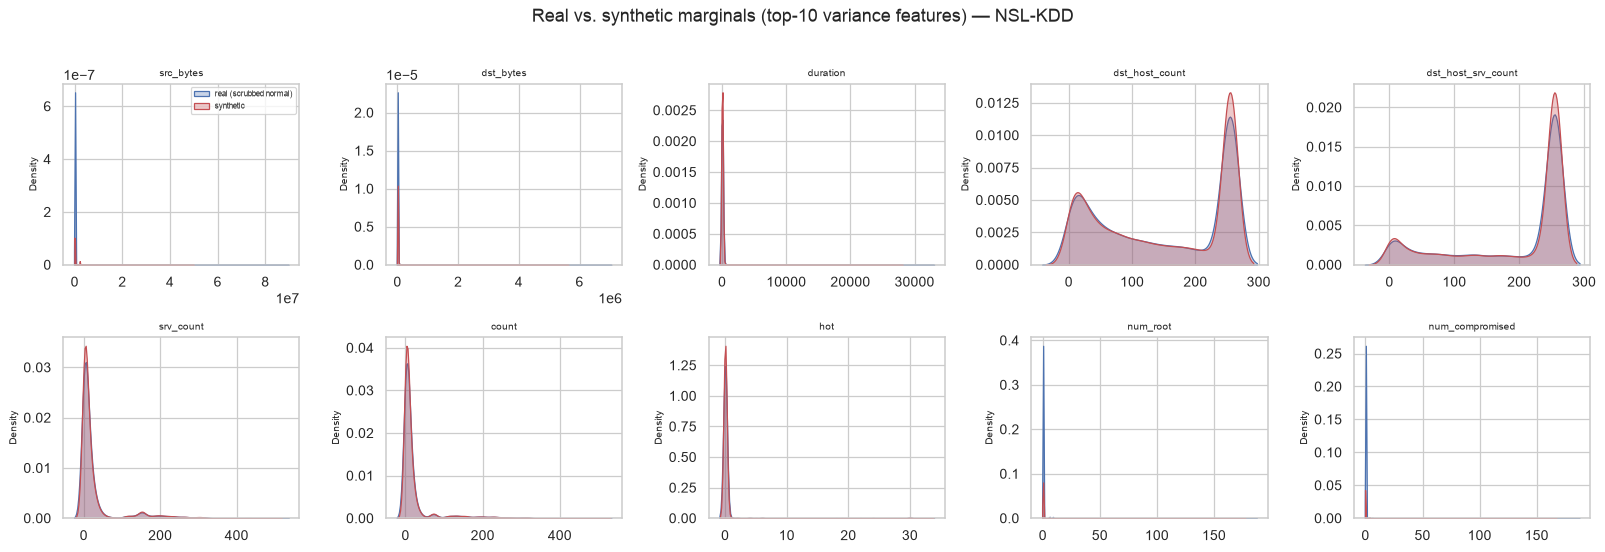

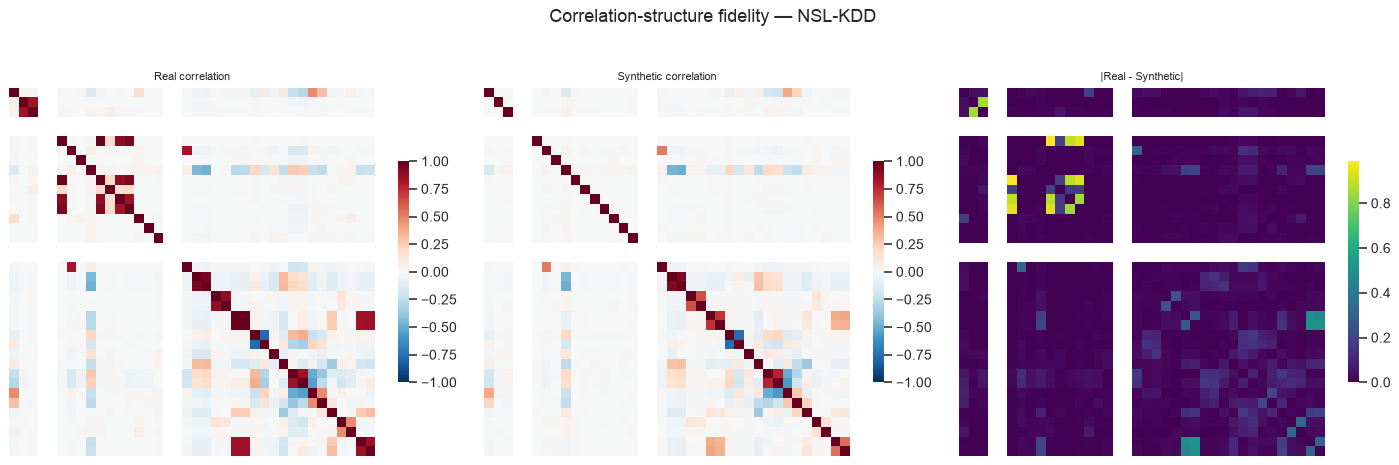

Mean absolute correlation error: nan


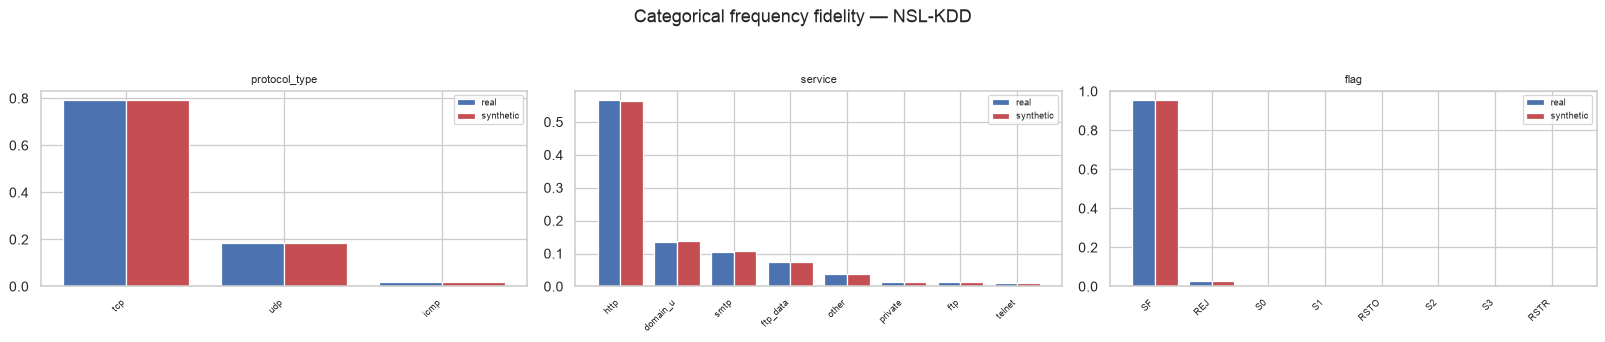

In [8]:
fidelity_diagnostics("NSL-KDD", nslkdd_result)

## 6. Run — UNSW-NB15

##########################################################################################
# UNSW-NB15
##########################################################################################
Hardcoded zero-variance columns (excluded from modelling): []



80% generator-fitting split: 40000 rows -> 27440 scrubbed normals
20% local holdout (never used for fitting): 10000 rows (30.0% abnormal)


Enforcing hard logical/algebraic relations:
  nontcp_fields_zeroed: corrected 0 rows
  tcprtt_consistency: recomputed for 52157 rows with drift > 1e-9



[copula_generator] AUPRC_ECOD=0.4751  AUPRC_IForest=0.4737  S=0.4744



[bootstrap_jitter_baseline] AUPRC_ECOD=0.4625  AUPRC_IForest=0.4586  S=0.4606



[real_normal_ceiling] AUPRC_ECOD=0.4779  AUPRC_IForest=0.4854  S=0.4817


,AUPRC_ECOD,AUPRC_IForest,S
copula_generator,0.47514,0.47368,0.47441
bootstrap_jitter_baseline,0.462543,0.45856,0.460552
real_normal_ceiling,0.477896,0.485439,0.481667


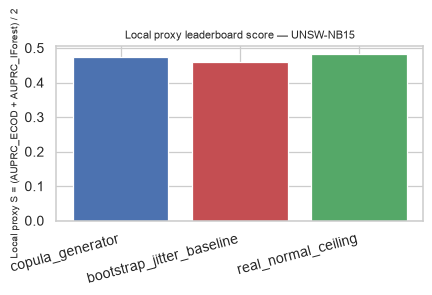


Full scrubbed normal set for final submission: 34300 rows (required submission size N=70000; 2.04x the unique real-normal rows available, so most submitted rows must be genuinely interpolated, not replayed real rows).


Enforcing hard logical/algebraic relations:
  nontcp_fields_zeroed: corrected 0 rows
  tcprtt_consistency: recomputed for 52174 rows with drift > 1e-9
Validation passed: 70000 rows x 42 columns, no NaN/inf, schema matches training data.


Saved submission -> submissions/submission_unsw.csv  shape=(70000, 43)


In [9]:
unsw_result = run_pipeline("UNSW-NB15")

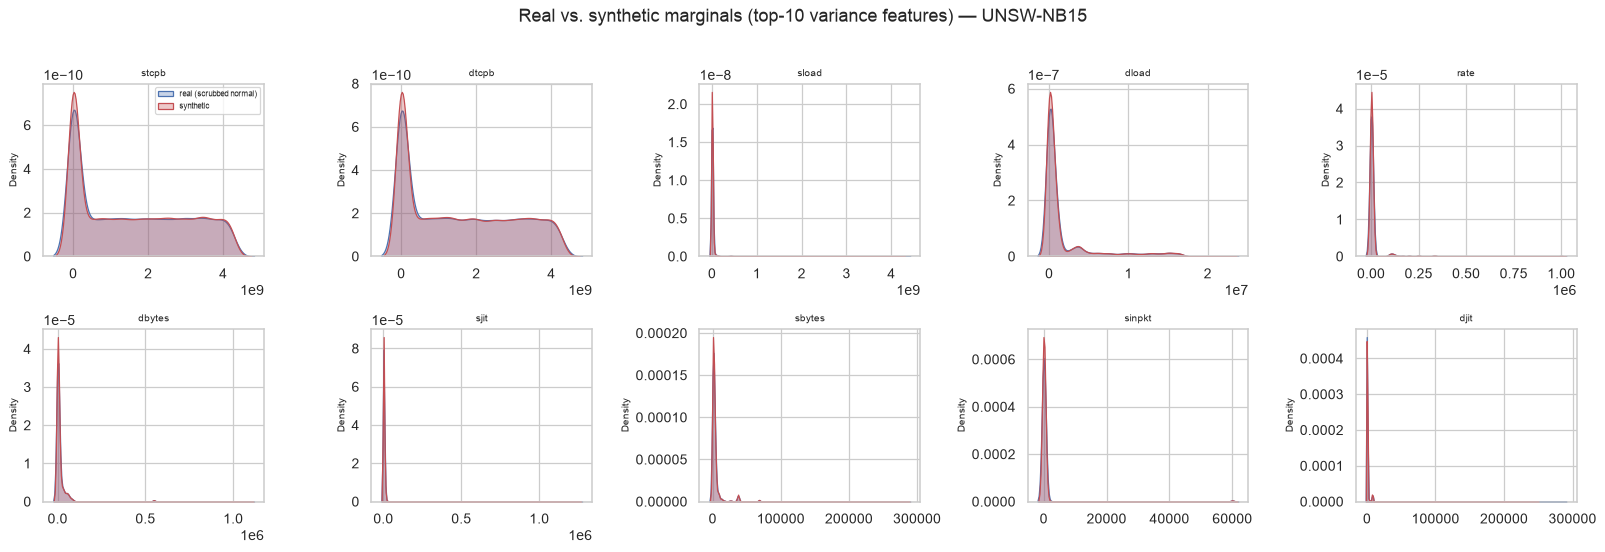

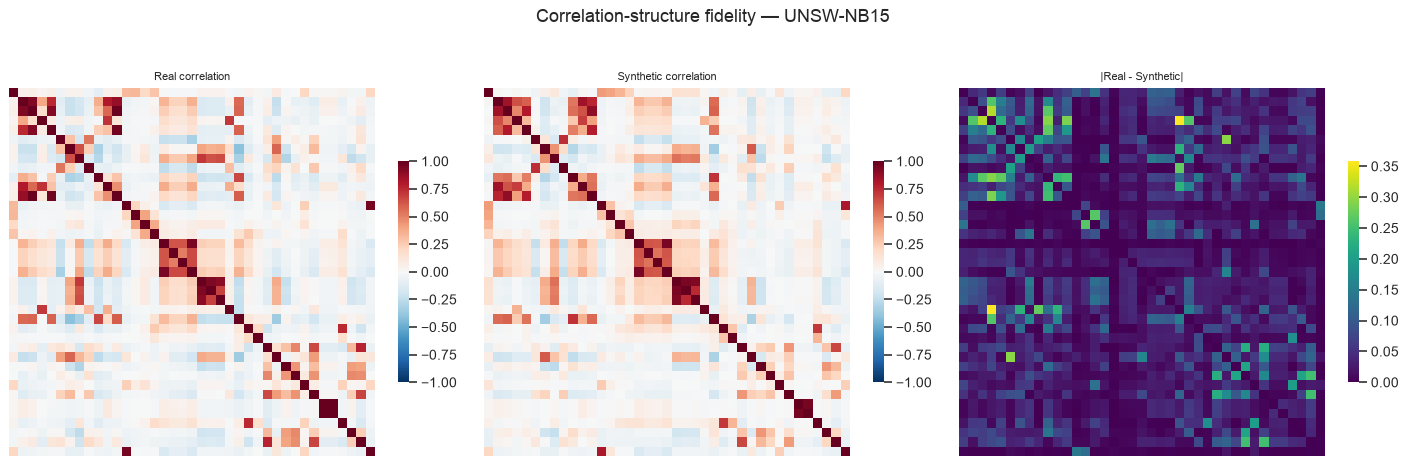

Mean absolute correlation error: 0.0420


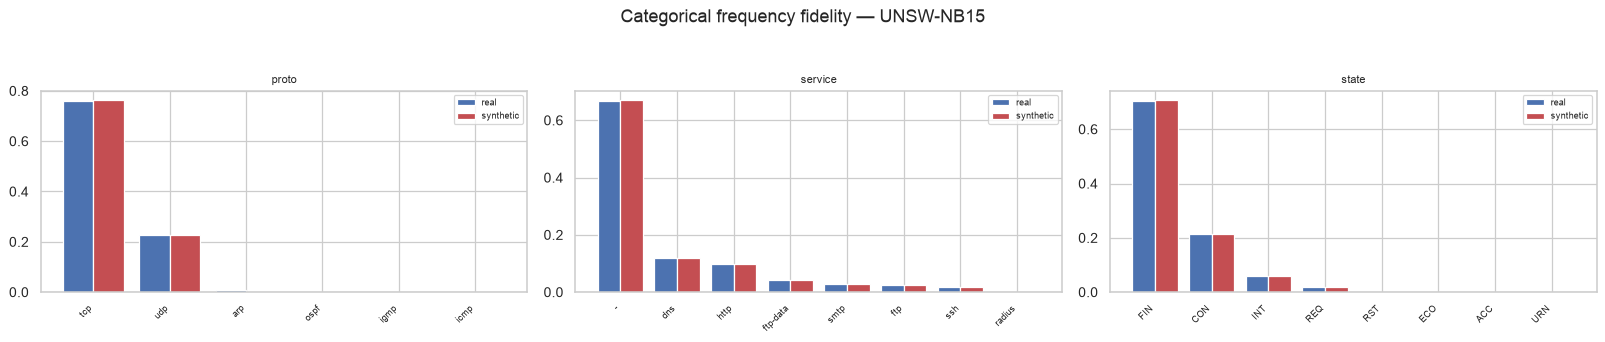

In [10]:
fidelity_diagnostics("UNSW-NB15", unsw_result)

## 7. Cross-dataset results summary

In [11]:

combined = pd.concat(
    {name: res["proxy_table"] for name, res in [("NSL-KDD", nslkdd_result), ("UNSW-NB15", unsw_result)]},
    names=["dataset", "candidate"],
)
display(combined)
combined.to_csv(SUB_DIR / "local_proxy_results.csv")
print("\nSaved local proxy comparison -> submissions/local_proxy_results.csv")
print("Final Kaggle submissions -> submissions/submission_nslkdd.csv, submissions/submission_unsw.csv")


AUPRC_ECOD AUPRC_IForest         S
dataset   candidate                                                   
NSL-KDD   copula_generator            0.938274      0.963128  0.950701
          bootstrap_jitter_baseline   0.940627      0.963588  0.952108
          real_normal_ceiling         0.940498      0.969082   0.95479
UNSW-NB15 copula_generator             0.47514       0.47368   0.47441
          bootstrap_jitter_baseline   0.462543       0.45856  0.460552
          real_normal_ceiling         0.477896      0.485439  0.481667


Saved local proxy comparison -> submissions/local_proxy_results.csv
Final Kaggle submissions -> submissions/submission_nslkdd.csv, submissions/submission_unsw.csv



## 8. Interpreting the local proxy results & next steps

- If **`copula_generator` beats `bootstrap_jitter_baseline`** on `S` for both datasets, that's
  evidence the conditional copula's preserved correlation structure and per-protocol marginals
  are adding real downstream utility over naive bootstrap+jitter — worth leading with in the
  report.
- The **`real_normal_ceiling`** row is the practical upper bound achievable at this sample size
  with zero synthesis error; the gap between it and `copula_generator` quantifies how much
  utility is still being left on the table by the generation method, and is a natural
  "future work" quantity to report.
- Remember the caveats from Section 0: this proxy holdout has **no unseen attack types**, so a
  method that wins locally may still need to demonstrate (via the report's explainability
  requirement) *why* its normal-boundary should generalize to novel anomalies — e.g. by
  showing the PCA/coverage diagnostics from `EDA.ipynb` alongside these AUPRC numbers.
- Before the first real Kaggle submission, sanity-check `submissions/submission_*.csv` against
  the actual competition's required `N` and column-order conventions (this notebook uses the
  competition-confirmed fixed sizes `N = 40,000` for NSL-KDD and `N = 70,000` for UNSW-NB15,
  both far larger than the number of unique scrubbed-normal real rows available — see Section 3
  note on why this makes the copula's ability to interpolate genuinely new points, not just
  replay real rows, more consequential at submission scale than at the smaller proxy scale).
